# 04 Explaining A2 (WavLM + layer-weighted head)
A2 averages each of WavLM's 13 layers over time, mixes them with learned weights, then a small MLP. Time is averaged away, so instead of frames we look at layers and at silence.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from audio_df.data.manifests import load_manifest
from audio_df.helpers.eval_audio import trimmed_manifest
from audio_df.helpers.metrics import compute_eer, min_dcf
from audio_df.helpers.ssl_cache import cached_pooled, iter_pooled_chunks
from audio_df.modules.ssl_detector import SSLDetector

CACHE = Path("../data/cache").resolve()  # absolute, so cache identities match the runtime's
art = Path("../artifacts/a2/20261023-200629-150334")  # trimmed-trained A2, tracked in git
prep = art / "preprocessing.json"
train_audio = json.loads(prep.read_text())["train"] if prep.exists() else "raw"
a2 = SSLDetector.load(art, device="auto")  # GPU (if any) only for building missing WavLM caches
a2.head.cpu()
print(art.name, "| trained on", train_audio, "audio")

def eer(scores, labels):
    return round(100 * compute_eer(scores, labels, higher_is_spoof=False)[0], 2)

def feats(df, split):  # cached [clips, 13 layers, 768], no WavLM run when cached
    return cached_pooled(df, a2.encoder, CACHE / "wavlm-base-plus/pooled", split).astype(np.float32)

train, dev = load_manifest("../data/manifests/train.csv", ".."), load_manifest("../data/manifests/dev.csv", "..")
if train_audio == "trimmed":
    train = trimmed_manifest(train, CACHE, "train")
sets = {"train": train, "dev raw": dev, "dev trimmed": trimmed_manifest(dev, CACHE, "dev")}
X = {k: feats(v, "train" if k == "train" else "dev") for k, v in sets.items()}
y = {k: v.label.to_numpy() for k, v in sets.items()}

d:\MyCode\projects\GC2-EchoJEV\SystemCode\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using CUDA device: NVIDIA GeForce RTX 3060 Laptop GPU
20261023-200629-150334 | trained on trimmed audio
Trim audio train: cache hit (25,380 clips)
Trim audio dev: cache hit (24,844 clips)
WavLM train: 25,380 clips, 50 chunks, batch_size=8, workers=0, device=cuda
WavLM cache: D:\MyCode\projects\GC2-EchoJEV\SystemCode\data\cache\wavlm-base-plus\pooled\train\78f4884a51506275


WavLM train: 100%|██████████| 50/50 [00:00<00:00, 657.11chunk/s]


WavLM train: reused 50/50 cached chunks
WavLM dev: 24,844 clips, 49 chunks, batch_size=8, workers=0, device=cuda
WavLM cache: D:\MyCode\projects\GC2-EchoJEV\SystemCode\data\cache\wavlm-base-plus\pooled\dev\2e42d93aa125fa4e


WavLM dev: 100%|██████████| 49/49 [00:00<00:00, 60.28chunk/s]


WavLM dev: reused 49/49 cached chunks
WavLM dev: 24,844 clips, 49 chunks, batch_size=8, workers=0, device=cuda
WavLM cache: D:\MyCode\projects\GC2-EchoJEV\SystemCode\data\cache\wavlm-base-plus\pooled\dev\850ad90ecae49d73


WavLM dev: 100%|██████████| 49/49 [00:00<00:00, 62.53chunk/s]


WavLM dev: reused 49/49 cached chunks


## 1 Learned layer weights

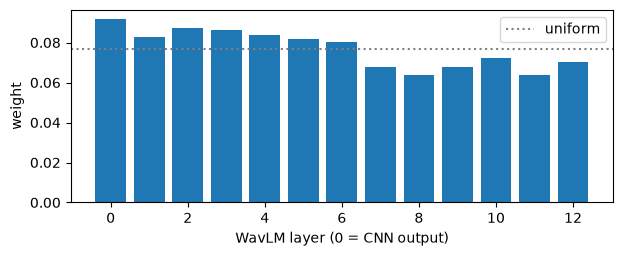

In [2]:
w = a2.head.layer_weights().detach().numpy()
plt.figure(figsize=(7, 2.5))
plt.bar(range(13), w)
plt.axhline(1 / 13, color="grey", ls=":", label="uniform")
plt.xlabel("WavLM layer (0 = CNN output)")
plt.ylabel("weight")
plt.legend()
plt.show()

Almost uniform (0.064–0.092), slightly more on layers 0–6 than 7–12. The head barely picks a layer, it mostly averages all 13.

## 2 What does each layer know?
A linear probe per layer, trained on train, scored on raw and trimmed dev. Dashed lines = A2 itself.

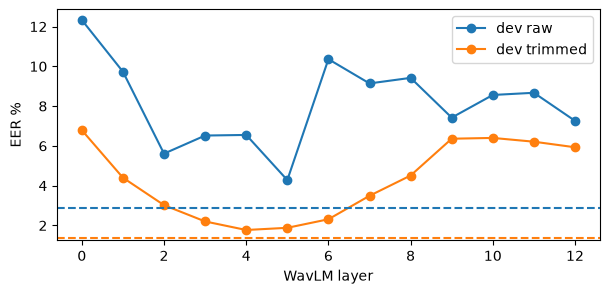

,0,1,2,3,4,5,6,7,8,9,10,11,12,A2
dev raw,12.33,9.73,5.61,6.52,6.55,4.28,10.36,9.14,9.42,7.42,8.56,8.67,7.26,2.87
dev trimmed,6.79,4.40,3.02,2.20,1.77,1.88,2.31,3.49,4.51,6.36,6.40,6.21,5.93,1.37


In [3]:
def fit_probe(layer):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1, class_weight="balanced"))
    return clf.fit(X["train"][:, layer], y["train"] == "bonafide")  # positive class = bona fide, like A2

def a2_scores(x):
    with torch.inference_mode():
        return a2.head(torch.from_numpy(x)).numpy()

probes = [fit_probe(l) for l in range(13)]
layers = pd.DataFrame({l: {k: eer(probes[l].decision_function(X[k][:, l]), y[k]) for k in ["dev raw", "dev trimmed"]}
                       for l in range(13)}).T
full = {k: eer(a2_scores(X[k]), y[k]) for k in ["dev raw", "dev trimmed"]}
ax = layers.plot(marker="o", figsize=(7, 3), ylabel="EER %", xlabel="WavLM layer")
for k, c in zip(full, ["C0", "C1"]):
    ax.axhline(full[k], color=c, ls="--")
plt.show()
layers.T.assign(A2=pd.Series(full))

On trimmed dev the middle layers are best: layer 4 gets 1.8%, layers 3–6 stay under 2.5%, close to A2 itself (1.4%). Both ends are weaker: layer 0 (CNN output) 6.8%, layers 9–12 about 6%. Layer 12 is what round 2's D2/D3 used.

## 2b Which layer holds up on every test set?
The same 13 probes (trained once, on train) scored on 2019 eval, its degraded copies (MP3, MUSAN noise, Opus, 8 kHz), In-the-Wild and ASVspoof 2021 LA. Missing WavLM caches are built first. minDCF uses the project costs (miss 1, false alarm 10, spoof prior 0.05).

Trim audio eval: cache hit (71,237 clips)
WavLM eval: 71,237 clips, 140 chunks, batch_size=8, workers=0, device=cuda
WavLM cache: D:\MyCode\projects\GC2-EchoJEV\SystemCode\data\cache\wavlm-base-plus\pooled\eval\decf5ccbba32b0c7


WavLM eval: 100%|██████████| 140/140 [00:26<00:00,  5.32chunk/s]


WavLM eval: reused 140/140 cached chunks
Trim audio eval_mp3_32k: cache hit (10,000 clips)
WavLM eval_mp3_32k: 10,000 clips, 20 chunks, batch_size=8, workers=0, device=cuda
WavLM cache: D:\MyCode\projects\GC2-EchoJEV\SystemCode\data\cache\wavlm-base-plus\pooled\eval_mp3_32k\662087c53df15832


WavLM eval_mp3_32k: 100%|██████████| 20/20 [00:02<00:00,  6.72chunk/s]


WavLM eval_mp3_32k: reused 20/20 cached chunks
Trim audio eval_noise_10db: cache hit (10,000 clips)
WavLM eval_noise_10db: 10,000 clips, 20 chunks, batch_size=8, workers=0, device=cuda
WavLM cache: D:\MyCode\projects\GC2-EchoJEV\SystemCode\data\cache\wavlm-base-plus\pooled\eval_noise_10db\63d94d0ed8fd4c2b


...

WavLM itw: reused 63/63 cached chunks
WavLM asvspoof2021_eval: 148,176 clips, 290 chunks, batch_size=8, workers=0, device=cuda
WavLM cache: D:\MyCode\projects\GC2-EchoJEV\SystemCode\data\cache\wavlm-base-plus\pooled\asvspoof2021_eval\808d3a265c46707f


WavLM asvspoof2021_eval: 100%|██████████| 290/290 [00:47<00:00,  6.12chunk/s]


WavLM asvspoof2021_eval: reused 290/290 cached chunks
WavLM asvspoof2021_hidden: 16,926 clips, 34 chunks, batch_size=8, workers=0, device=cuda
WavLM cache: D:\MyCode\projects\GC2-EchoJEV\SystemCode\data\cache\wavlm-base-plus\pooled\asvspoof2021_hidden\92a32dbf6f588674


WavLM asvspoof2021_hidden: 100%|██████████| 34/34 [00:06<00:00,  5.43chunk/s]


WavLM asvspoof2021_hidden: reused 34/34 cached chunks


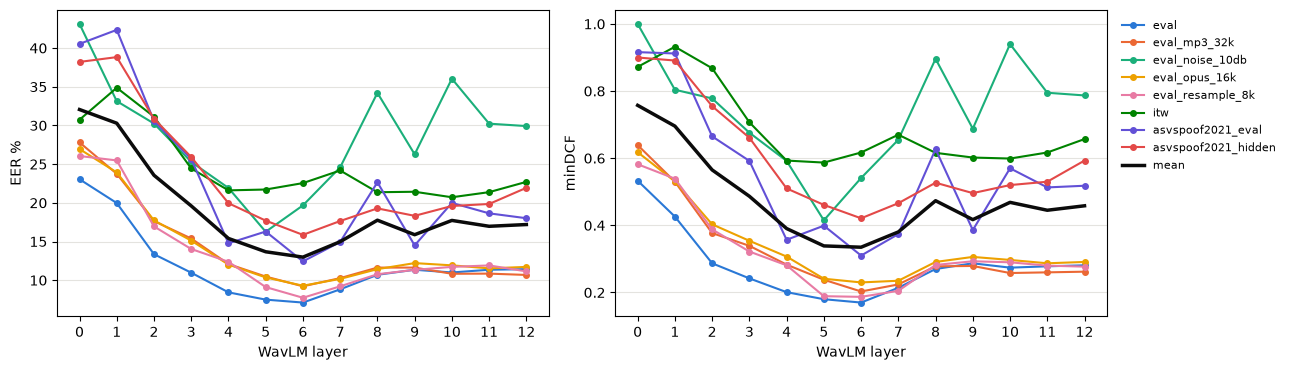

best layer by mean EER: 6 | by mean minDCF: 6


,0,1,2,3,4,5,6,7,8,9,10,11,12,A2
eval,23.05,19.97,13.36,10.97,8.43,7.49,7.11,8.82,10.70,11.35,11.00,11.35,11.43,7.64
eval_mp3_32k,27.81,23.75,17.64,15.39,12.09,10.47,9.21,10.27,11.63,11.63,10.83,10.85,10.68,8.42
eval_noise_10db,43.12,33.14,30.25,25.29,21.92,16.26,19.67,24.59,34.21,26.27,36.04,30.23,29.92,16.95
eval_opus_16k,26.95,23.93,17.73,15.12,12.02,10.36,9.29,10.17,11.43,12.21,11.92,11.53,11.72,7.96
eval_resample_8k,26.05,25.48,16.95,14.03,12.38,9.11,7.73,9.21,10.77,11.34,11.72,11.91,11.14,7.45
itw,30.74,34.87,31.13,24.44,21.61,21.72,22.55,24.18,21.37,21.43,20.72,21.38,22.71,19.17
asvspoof2021_eval,40.54,42.35,30.58,25.67,14.77,16.29,12.43,14.94,22.65,14.50,19.99,18.64,18.01,14.28
asvspoof2021_hidden,38.21,38.83,30.87,25.92,19.95,17.70,15.86,17.65,19.28,18.32,19.59,19.85,21.94,20.92
mean,32.06,30.29,23.56,19.60,15.40,13.68,12.98,14.98,17.76,15.88,17.73,16.97,17.19,12.85


In [4]:
TESTS = ["eval", "eval_mp3_32k", "eval_noise_10db", "eval_opus_16k", "eval_resample_8k", "itw",
         "asvspoof2021_eval", "asvspoof2021_hidden"]

def test_scores(name):  # stream cache chunks: 13 probe scores + A2's score per clip
    df = load_manifest(f"../data/manifests/{name}.csv", "..")
    if name == "eval" or name.startswith("eval_"):  # 2019 sets are trimmed, like the runtime
        df = trimmed_manifest(df, CACHE, name)
    parts = [[] for _ in range(14)]
    for chunk in iter_pooled_chunks(df, a2.encoder, CACHE / "wavlm-base-plus/pooled", name):
        x = np.asarray(chunk, np.float32)
        for l in range(13):
            parts[l].append(probes[l].decision_function(x[:, l]))
        parts[13].append(a2_scores(x))
    return df.label.to_numpy(), [np.concatenate(p) for p in parts]

cols = [*range(13), "A2"]
EER, DCF = pd.DataFrame(columns=cols, dtype=float), pd.DataFrame(columns=cols, dtype=float)
for name in TESTS:
    labels, scores = test_scores(name)
    EER.loc[name] = [eer(s, labels) for s in scores]
    DCF.loc[name] = [round(min_dcf(s, labels, higher_is_spoof=False)[0], 3) for s in scores]
for t in (EER, DCF):
    t.loc["mean"] = t.mean()

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
for ax, t, label in [(axes[0], EER, "EER %"), (axes[1], DCF, "minDCF")]:
    for name, color in zip(TESTS, COLORS):
        ax.plot(range(13), t.loc[name, list(range(13))], marker="o", ms=4, lw=1.5, color=color, label=name)
    ax.plot(range(13), t.loc["mean", list(range(13))], color="#0b0b0b", lw=2.5, label="mean")
    ax.set_xticks(range(13))
    ax.set_xlabel("WavLM layer")
    ax.set_ylabel(label)
    ax.grid(axis="y", color="#e4e3df")
axes[1].legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
plt.show()
print("best layer by mean EER:", EER.loc["mean", list(range(13))].idxmin(),
      "| by mean minDCF:", DCF.loc["mean", list(range(13))].idxmin())
EER.round(2)

In [5]:
DCF

,0,1,2,3,4,5,6,7,8,9,10,11,12,A2
eval,0.5330,0.426000,0.287000,0.242000,0.2010,0.18000,0.170000,0.214000,0.270000,0.287000,0.2740,0.278,0.28100,0.15800
eval_mp3_32k,0.6390,0.530000,0.377000,0.339000,0.2830,0.23800,0.203000,0.224000,0.278000,0.279000,0.2580,0.260,0.26200,0.17600
eval_noise_10db,1.0000,0.804000,0.778000,0.676000,0.5920,0.41500,0.541000,0.655000,0.896000,0.688000,0.9400,0.795,0.78700,0.42900
eval_opus_16k,0.6180,0.531000,0.403000,0.354000,0.3070,0.24100,0.230000,0.235000,0.291000,0.306000,0.2970,0.287,0.29100,0.18100
eval_resample_8k,0.5820,0.539000,0.388000,0.322000,0.2810,0.18900,0.187000,0.205000,0.282000,0.293000,0.2900,0.280,0.27700,0.15100
itw,0.8720,0.932000,0.868000,0.707000,0.5930,0.58700,0.617000,0.670000,0.616000,0.602000,0.5990,0.617,0.65700,0.51500
asvspoof2021_eval,0.9160,0.912000,0.665000,0.592000,0.3570,0.39900,0.310000,0.374000,0.627000,0.386000,0.5700,0.513,0.51800,0.34600
asvspoof2021_hidden,0.9000,0.891000,0.755000,0.661000,0.5100,0.46100,0.421000,0.466000,0.527000,0.496000,0.5200,0.530,0.59300,0.53400
mean,0.7575,0.695625,0.565125,0.486625,0.3905,0.33875,0.334875,0.380375,0.473375,0.417125,0.4685,0.445,0.45825,0.31125


Dev alone picks layer 4, but averaged over all 8 test sets layer 6 is best by both metrics (mean EER 13.0%, minDCF 0.335), about as good as A2's full mix (12.9%, 0.311) and better than it on 2021 LA eval (12.4% vs 14.3%). Layer 5 is a close second and the best single layer under MUSAN noise (16.3%). Layer 12 averages 17.2%. Round 3 D2/D3 use layer 6.

## 3 Silence test
Same A2, same dev clips, raw vs trimmed audio.

          dev raw  dev trimmed
bonafide     9.40         9.44
spoof      -14.77       -21.00


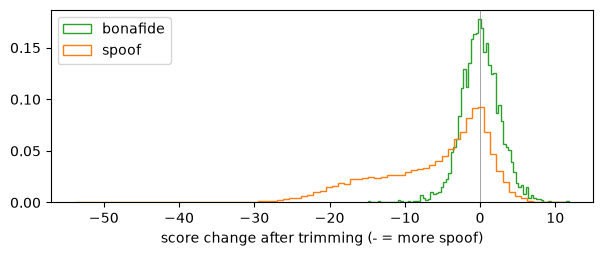

In [6]:
s = {k: a2_scores(X[k]) for k in ["dev raw", "dev trimmed"]}
shift = s["dev trimmed"] - s["dev raw"]
print(pd.DataFrame({k: pd.Series(v).groupby(y[k]).mean() for k, v in s.items()}).round(2))
plt.figure(figsize=(7, 2.5))
for lab, color in [("bonafide", "tab:green"), ("spoof", "tab:orange")]:
    plt.hist(shift[y["dev raw"] == lab], bins=80, density=True, histtype="step", color=color, label=lab)
plt.axvline(0, color="grey", lw=0.5)
plt.xlabel("score change after trimming (- = more spoof)")
plt.legend()
plt.show()

Trimming barely moves either class now: bona fide 9.40 → 9.44, spoof -14.8 → -21.0 (more spoof-like). Training on trimmed audio removed the silence shortcut; the round 1 A2 dropped about 11 points on bona fide here.